In [327]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder,OrdinalEncoder, LabelEncoder, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet, SGDRegressor, LogisticRegression
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, f1_score, precision_recall_curve, precision_score, recall_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, GradientBoostingRegressor
from sklearn.base import clone


In [328]:
df = pd.read_csv("Metro_Interstate_Traffic_Volume.csv")
print(df.shape)
display(df)

(48204, 9)


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918
...,...,...,...,...,...,...,...,...,...
48199,NaN,283.45,0.0,0.0,75,Clouds,broken clouds,2018-09-30 19:00:00,3543
48200,NaN,282.76,0.0,0.0,90,Clouds,overcast clouds,2018-09-30 20:00:00,2781
48201,NaN,282.73,0.0,0.0,90,Thunderstorm,proximity thunderstorm,2018-09-30 21:00:00,2159
48202,NaN,282.09,0.0,0.0,90,Clouds,overcast clouds,2018-09-30 22:00:00,1450


In [329]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   holiday              61 non-null     str    
 1   temp                 48204 non-null  float64
 2   rain_1h              48204 non-null  float64
 3   snow_1h              48204 non-null  float64
 4   clouds_all           48204 non-null  int64  
 5   weather_main         48204 non-null  str    
 6   weather_description  48204 non-null  str    
 7   date_time            48204 non-null  str    
 8   traffic_volume       48204 non-null  int64  
dtypes: float64(3), int64(2), str(4)
memory usage: 3.3 MB


In [330]:
print(f"Null values Per feature:\n\n{df.isnull().sum()}")
print("\nDuplicate instances: ", df.duplicated().sum())

Null values Per feature:

holiday                48143
temp                       0
rain_1h                    0
snow_1h                    0
clouds_all                 0
weather_main               0
weather_description        0
date_time                  0
traffic_volume             0
dtype: int64

Duplicate instances:  17


In [331]:
df["holiday"].value_counts()

holiday
Labor Day                    7
Thanksgiving Day             6
Christmas Day                6
New Years Day                6
Martin Luther King Jr Day    6
Columbus Day                 5
Veterans Day                 5
Washingtons Birthday         5
Memorial Day                 5
Independence Day             5
State Fair                   5
Name: count, dtype: int64

In [332]:
df["holiday"] = df["holiday"].fillna("None")

In [333]:
print(df.shape)
df.drop_duplicates(inplace=True)
print(df.shape)

(48204, 9)
(48187, 9)


In [334]:
df.isnull().sum()

holiday                0
temp                   0
rain_1h                0
snow_1h                0
clouds_all             0
weather_main           0
weather_description    0
date_time              0
traffic_volume         0
dtype: int64

In [335]:
X = df.drop("traffic_volume", axis = 1)
print(X.shape)
y = df["traffic_volume"]
print(y.shape)

(48187, 8)
(48187,)


In [336]:
X.select_dtypes(include = "object").info()

<class 'pandas.DataFrame'>
Index: 48187 entries, 0 to 48203
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   holiday              48187 non-null  str  
 1   weather_main         48187 non-null  str  
 2   weather_description  48187 non-null  str  
 3   date_time            48187 non-null  str  
dtypes: str(4)
memory usage: 1.8 MB


C:\Users\PC\AppData\Local\Temp\ipykernel_21808\2239480879.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  X.select_dtypes(include = "object").info()


In [337]:
X["date_time"].value_counts()

date_time
2013-04-18 22:00:00    6
2013-05-19 10:00:00    6
2012-10-25 15:00:00    5
2012-10-26 04:00:00    5
2012-11-11 04:00:00    5
                      ..
2018-09-30 19:00:00    1
2018-09-30 20:00:00    1
2018-09-30 21:00:00    1
2018-09-30 22:00:00    1
2018-09-30 23:00:00    1
Name: count, Length: 40575, dtype: int64

In [338]:
X.loc[X["date_time"].duplicated(),"date_time"].value_counts()


date_time
2013-04-18 22:00:00    5
2013-05-19 10:00:00    5
2012-10-25 15:00:00    4
2012-10-26 04:00:00    4
2012-11-11 04:00:00    4
                      ..
2018-09-25 14:00:00    1
2018-09-25 16:00:00    1
2018-09-27 07:00:00    1
2018-09-30 14:00:00    1
2018-09-30 15:00:00    1
Name: count, Length: 5430, dtype: int64

Since date_time has duplicated values, we have to check if they have meaningful information or not.<br>
The Traffic volume (target variable) for each one of these rows is the same.<br>
Therefore we drop these rows.

In [339]:
ymap = pd.DataFrame(y)

print("Before:")
print("X's Shape:", X.shape, "y's Shape:", ymap.shape)

# Add target to X
X["y_map"] = y

# Remove duplicated timestamps
X.drop_duplicates(subset="date_time", inplace=True)

# Extract the target after removing duplicates
y = X["y_map"].copy()

# Remove target column from X
X.drop("y_map", axis=1, inplace=True)

print("After:")
print("X's Shape:", X.shape, "y's Shape:", y.shape)

Before:
X's Shape: (48187, 8) y's Shape: (48187, 1)
After:
X's Shape: (40575, 8) y's Shape: (40575,)


In [340]:
print(X.shape)
X["Year"] = pd.to_datetime(X["date_time"]).dt.year
X["Month"] = pd.to_datetime(X["date_time"]).dt.month
X["Day"] = pd.to_datetime(X["date_time"]).dt.day
X["Hour (24h)"] = pd.to_datetime(X["date_time"]).dt.hour

X = X.drop('date_time', axis = 1)
print(X.shape)
display(X.head())

(40575, 8)
(40575, 11)


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,Year,Month,Day,Hour (24h)
0,None,288.28,0.0,0.0,40,Clouds,scattered clouds,2012,10,2,9
1,None,289.36,0.0,0.0,75,Clouds,broken clouds,2012,10,2,10
2,None,289.58,0.0,0.0,90,Clouds,overcast clouds,2012,10,2,11
3,None,290.13,0.0,0.0,90,Clouds,overcast clouds,2012,10,2,12
4,None,291.14,0.0,0.0,75,Clouds,broken clouds,2012,10,2,13


In [341]:
X["temp"].max()

np.float64(310.07)

Since the max temp is: "310". It can only be in kelvin <br>
Converting it to celsius:  temp(c) = temp(k)-273.15

In [342]:
X["Temp(Celsius)"] =  X["temp"] - 273.15
X = X.drop("temp", axis = 1) 
X.head()

,holiday,rain_1h,snow_1h,clouds_all,weather_main,weather_description,Year,Month,Day,Hour (24h),Temp(Celsius)
0,None,0.0,0.0,40,Clouds,scattered clouds,2012,10,2,9,15.13
1,None,0.0,0.0,75,Clouds,broken clouds,2012,10,2,10,16.21
2,None,0.0,0.0,90,Clouds,overcast clouds,2012,10,2,11,16.43
3,None,0.0,0.0,90,Clouds,overcast clouds,2012,10,2,12,16.98
4,None,0.0,0.0,75,Clouds,broken clouds,2012,10,2,13,17.99


Our Dateset min year is "2012" ad max year is "2018"
<li>Lowest temp in USA (2012-2018): −54.4 °C (approx) <br>
<li>Highest temp in USA (2012 - 2018): 54.0 °C (approx) <br><br>
Impute any anomaly, lower than -54.4 or higher than 54.0

In [343]:
X.loc[(X['Temp(Celsius)']<-54.4) | (X["Temp(Celsius)"]> 54), ["Temp(Celsius)","weather_main","Year", "Month","Hour (24h)"]]


,Temp(Celsius),weather_main,Year,Month,Hour (24h)
11898,-273.15,Clear,2014,1,3
11899,-273.15,Clear,2014,1,4
11900,-273.15,Clear,2014,1,5
11901,-273.15,Clear,2014,1,6
11946,-273.15,Clear,2014,2,3
11947,-273.15,Clear,2014,2,4
11948,-273.15,Clear,2014,2,5
11949,-273.15,Clear,2014,2,6
11950,-273.15,Clear,2014,2,7
11951,-273.15,Clear,2014,2,8


In [344]:
print(X["Year"].min())
print(X["Year"].max())

2012
2018


The estimated average U.S. temperature during clear early mornings (3:00 AM–8:00 AM) in January–February 2014 was approximately -7.2°C (19°F).


In [345]:
X["Temp(Celsius)"] = X["Temp(Celsius)"].replace(-273.15, -7.2)

In [346]:
X["holiday"].value_counts()

holiday
None                         40522
Columbus Day                     5
Veterans Day                     5
Thanksgiving Day                 5
Christmas Day                    5
New Years Day                    5
Washingtons Birthday             5
Memorial Day                     5
Independence Day                 5
State Fair                       5
Labor Day                        5
Martin Luther King Jr Day        3
Name: count, dtype: int64

In [347]:
X["weather_description"].value_counts()

weather_description
sky is clear                           11642
overcast clouds                         5072
broken clouds                           4650
scattered clouds                        3451
mist                                    3069
light rain                              2831
few clouds                              1950
Sky is Clear                            1724
light snow                              1588
moderate rain                           1379
haze                                     766
heavy snow                               500
heavy intensity rain                     408
light intensity drizzle                  360
proximity thunderstorm                   339
fog                                      201
snow                                     192
drizzle                                  138
proximity shower rain                    120
thunderstorm                              59
thunderstorm with light rain              23
very heavy rain                    

Here, the sky is clear is written  in two representations: "sky is clear" and "Sky is clear".<br>
To standardize each column we'll strip() and lower() it.

In [348]:
X["weather_description"] = X["weather_description"].str.strip().str.lower()
print(X["weather_description"].value_counts())
print(X["weather_description"].nunique())

weather_description
sky is clear                           13366
overcast clouds                         5072
broken clouds                           4650
scattered clouds                        3451
mist                                    3069
light rain                              2831
few clouds                              1950
light snow                              1588
moderate rain                           1379
haze                                     766
heavy snow                               500
heavy intensity rain                     408
light intensity drizzle                  360
proximity thunderstorm                   339
fog                                      201
snow                                     192
drizzle                                  138
proximity shower rain                    120
thunderstorm                              59
thunderstorm with light rain              23
very heavy rain                           18
heavy intensity drizzle            

In [349]:
pd.crosstab(X["weather_main"], X["weather_description"])

weather_description,broken clouds,drizzle,few clouds,fog,freezing rain,haze,heavy intensity drizzle,heavy intensity rain,heavy snow,light intensity drizzle,...,sleet,smoke,snow,squalls,thunderstorm,thunderstorm with heavy rain,thunderstorm with light drizzle,thunderstorm with light rain,thunderstorm with rain,very heavy rain
weather_main,,,,,,,,,,,,,,,,,,,,,
Clear,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Clouds,4650,0,1950,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Drizzle,0,138,0,0,0,0,17,0,0,360,...,0,0,0,0,0,0,0,0,0,0
Fog,0,0,0,201,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Haze,0,0,0,0,0,766,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Mist,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Rain,0,0,0,0,1,0,0,408,0,0,...,0,0,0,0,0,0,0,0,0,18
Smoke,0,0,0,0,0,0,0,0,0,0,...,0,15,0,0,0,0,0,0,0,0
Snow,0,0,0,0,0,0,0,0,500,0,...,3,0,192,0,0,0,0,0,0,0


In [350]:
X["weather_main"].value_counts()

weather_main
Clouds          15123
Clear           13366
Rain             4769
Mist             3069
Snow             2297
Haze              766
Drizzle           515
Thunderstorm      453
Fog               201
Smoke              15
Squall              1
Name: count, dtype: int64

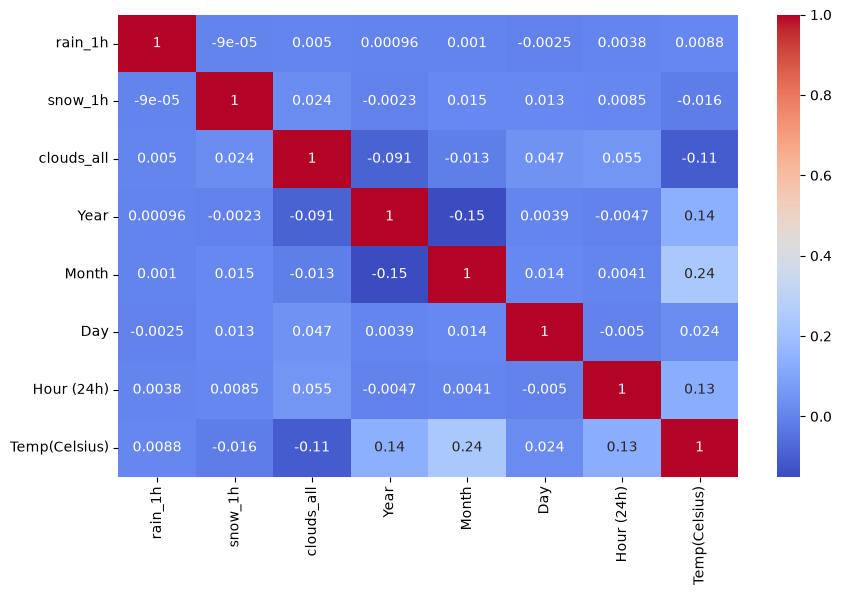

In [351]:
plt.figure(figsize=(10,6))
sns.heatmap(X.select_dtypes(include = "number").corr(), annot= True, cmap = "coolwarm")
plt.show()

In [352]:
Categorical_Features = X.select_dtypes(include = 'object').columns.to_list()
Numerical_Features = X.select_dtypes(include= "number").columns.to_list()
print(Categorical_Features)
print(Numerical_Features)

['holiday', 'weather_main', 'weather_description']
['rain_1h', 'snow_1h', 'clouds_all', 'Year', 'Month', 'Day', 'Hour (24h)', 'Temp(Celsius)']


C:\Users\PC\AppData\Local\Temp\ipykernel_21808\2019034208.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  Categorical_Features = X.select_dtypes(include = 'object').columns.to_list()


# Encoding / Scalling Pipeline

In [353]:
Categorical_Pipeline = Pipeline([
    ("Encoding", OneHotEncoder(handle_unknown = "ignore"))
])

Numerical_Pipeline = Pipeline([
    ("Scaller", StandardScaler())
])

Polynomial_Numerical_Pipeline = Pipeline([
    ("Polynomial", PolynomialFeatures(
        degree=2,
        include_bias=False
    )),
    ("Scaler", StandardScaler())
])

### Chronological Train-Test Split

Since our model aims to predict future traffic volume, it is essential to evaluate its performance on data collected **after the training period**. Therefore, instead of using a random train-test split, we split the dataset chronologically based on the `date_time` feature.

This ensures that the model is trained on historical traffic patterns and tested on future observations, preventing future data from influencing the training process and providing a more realistic evaluation of its forecasting performance.

In [354]:
# Get timestamps corresponding to the rows in X
dates = pd.to_datetime(df.loc[X.index, "date_time"])

# Sort existing X and y chronologically
sorted_index = dates.sort_values().index

X = X.loc[sorted_index]
y = y.loc[sorted_index]

# Split without shuffling
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    shuffle=False
)


# Transformer

In [355]:
Transformer = ColumnTransformer([
    ('Numerical', Numerical_Pipeline, Numerical_Features),
    ("Categorical", Categorical_Pipeline, Categorical_Features)
])

Polynomial_Transformer = ColumnTransformer([
    ("Numerical", Polynomial_Numerical_Pipeline, Numerical_Features),
    ("Categorical", Categorical_Pipeline, Categorical_Features)
    ])


# Models

In [356]:
Linear_Model = Pipeline([
    ("Transformer", Transformer),
    ("Regressor", LinearRegression())
])

RandomForest_Model = Pipeline([
    ("Transformer", clone(Transformer)),
    ("Regressor", RandomForestRegressor(
        n_estimators=200,
        max_depth=15,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1))
])

Ridge_Model = Pipeline([
    ("Transformer", Transformer),
    ("Regressor", Ridge())
])

Lasso_Model = Pipeline([
    ("Transformer", Transformer),
    ("Regressor", Lasso())
])

ElasticNet_Model = Pipeline([
    ("Transformer", Transformer),
    ("Regressor", ElasticNet())
]) 

SGD_Model = Pipeline([
    ("Transformer", Transformer),
    ("Regressor", SGDRegressor())
])

GradientBoosting_Model = Pipeline([
    ("Transformer", clone(Transformer)),
    ("Regressor", GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

Polynomial_Model = Pipeline([
    ("Transformer", Polynomial_Transformer),
    ("Regressor", LinearRegression())
])


In [357]:
results = {}

def evaluate_regression(name, model, X_train, X_test, y_train, y_test):
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    metrics = {
        "Training Score": model.score(X_train, y_train),
        "Testing Score": model.score(X_test, y_test),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2 Score": r2_score(y_test, y_pred)
    }
    results.update({name: metrics})
    return metrics


def print_metrics(results, name=None):
    selected = {name: results[name]} if name is not None else results
    for model_name, metrics in selected.items():
        print(f"\n{model_name} Performance:")
        for metric, value in metrics.items():
            print(f"{metric}: {value:.4f}")


# Fitting the models + Evaluation

In [358]:
display(Linear_Model.fit(X_train, y_train))
evaluate_regression("Linear Regression", Linear_Model, X_train, X_test, y_train, y_test)
print_metrics(results, "Linear Regression")

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Transformer', ...), ('Regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['holiday','rain_1h','snow_1h',...,'Day','Hour (24h)','Temp(Celsius)']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Numerical', ...), ('Categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This s


Linear Regression Performance:
Training Score: 0.1515
Testing Score: 0.1553
MSE: 3278592.2638
RMSE: 1810.6883
R2 Score: 0.1553


In [359]:
display(Ridge_Model.fit(X_train, y_train))
evaluate_regression("Ridge Regression", Ridge_Model, X_train, X_test, y_train, y_test)
print_metrics(results, "Ridge Regression")

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Transformer', ...), ('Regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['holiday','rain_1h','snow_1h',...,'Day','Hour (24h)','Temp(Celsius)']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Numerical', ...), ('Categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This s


Ridge Regression Performance:
Training Score: 0.1515
Testing Score: 0.1554
MSE: 3278145.6916
RMSE: 1810.5650
R2 Score: 0.1554


In [360]:
display(Lasso_Model.fit(X_train, y_train))
evaluate_regression("Lasso Regression", Lasso_Model, X_train, X_test, y_train, y_test)
print_metrics(results, "Lasso Regression")

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Transformer', ...), ('Regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['holiday','rain_1h','snow_1h',...,'Day','Hour (24h)','Temp(Celsius)']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Numerical', ...), ('Categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This s


Lasso Regression Performance:
Training Score: 0.1501
Testing Score: 0.1550
MSE: 3279394.1508
RMSE: 1810.9098
R2 Score: 0.1550


In [361]:
display(ElasticNet_Model.fit(X_train, y_train))
evaluate_regression("ElasticNet Regression", ElasticNet_Model, X_train, X_test, y_train, y_test)
print_metrics(results, "ElasticNet Regression")

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Transformer', ...), ('Regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['holiday','rain_1h','snow_1h',...,'Day','Hour (24h)','Temp(Celsius)']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Numerical', ...), ('Categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This s


ElasticNet Regression Performance:
Training Score: 0.1299
Testing Score: 0.1364
MSE: 3351793.4253
RMSE: 1830.7904
R2 Score: 0.1364


In [362]:
display(SGD_Model.fit(X_train, y_train))
evaluate_regression("SGD Regression", SGD_Model, X_train, X_test, y_train, y_test)
print_metrics(results, "SGD Regression")

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Transformer', ...), ('Regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['holiday','rain_1h','snow_1h',...,'Day','Hour (24h)','Temp(Celsius)']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Numerical', ...), ('Categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This s


SGD Regression Performance:
Training Score: -345128941396.6241
Testing Score: -12504675.0143
MSE: 48532568393209.2656
RMSE: 6966532.0205
R2 Score: -12504675.0143


In [363]:
display(Polynomial_Model.fit(X_train, y_train))
evaluate_regression("Polynomial Regression", Polynomial_Model, X_train, X_test, y_train, y_test)
print_metrics(results, "Polynomial Regression")

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Transformer', ...), ('Regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['holiday','rain_1h','snow_1h',...,'Day','Hour (24h)','Temp(Celsius)']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Numerical', ...), ('Categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This s


Polynomial Regression Performance:
Training Score: 0.6595
Testing Score: 0.6548
MSE: 1339731.3318
RMSE: 1157.4676
R2 Score: 0.6548


In [368]:
display(RandomForest_Model.fit(X_train, y_train))
evaluate_regression("RandomForest Regression", RandomForest_Model, X_train, X_test, y_train, y_test)
print_metrics(results, "RandomForest Regression")

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Transformer', ...), ('Regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['holiday','rain_1h','snow_1h',...,'Day','Hour (24h)','Temp(Celsius)']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Numerical', ...), ('Categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This s


RandomForest Regression Performance:
Training Score: 0.8736
Testing Score: 0.7939
MSE: 799863.3217
RMSE: 894.3508
R2 Score: 0.7939


In [369]:
display(GradientBoosting_Model.fit(X_train, y_train))
evaluate_regression("GradientBoosting Regression", GradientBoosting_Model, X_train, X_test, y_train, y_test)
print_metrics(results, "GradientBoosting Regression")

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Transformer', ...), ('Regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['holiday','rain_1h','snow_1h',...,'Day','Hour (24h)','Temp(Celsius)']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Numerical', ...), ('Categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This s


GradientBoosting Regression Performance:
Training Score: 0.7949
Testing Score: 0.7922
MSE: 806557.5829
RMSE: 898.0855
R2 Score: 0.7922


## Evaluation

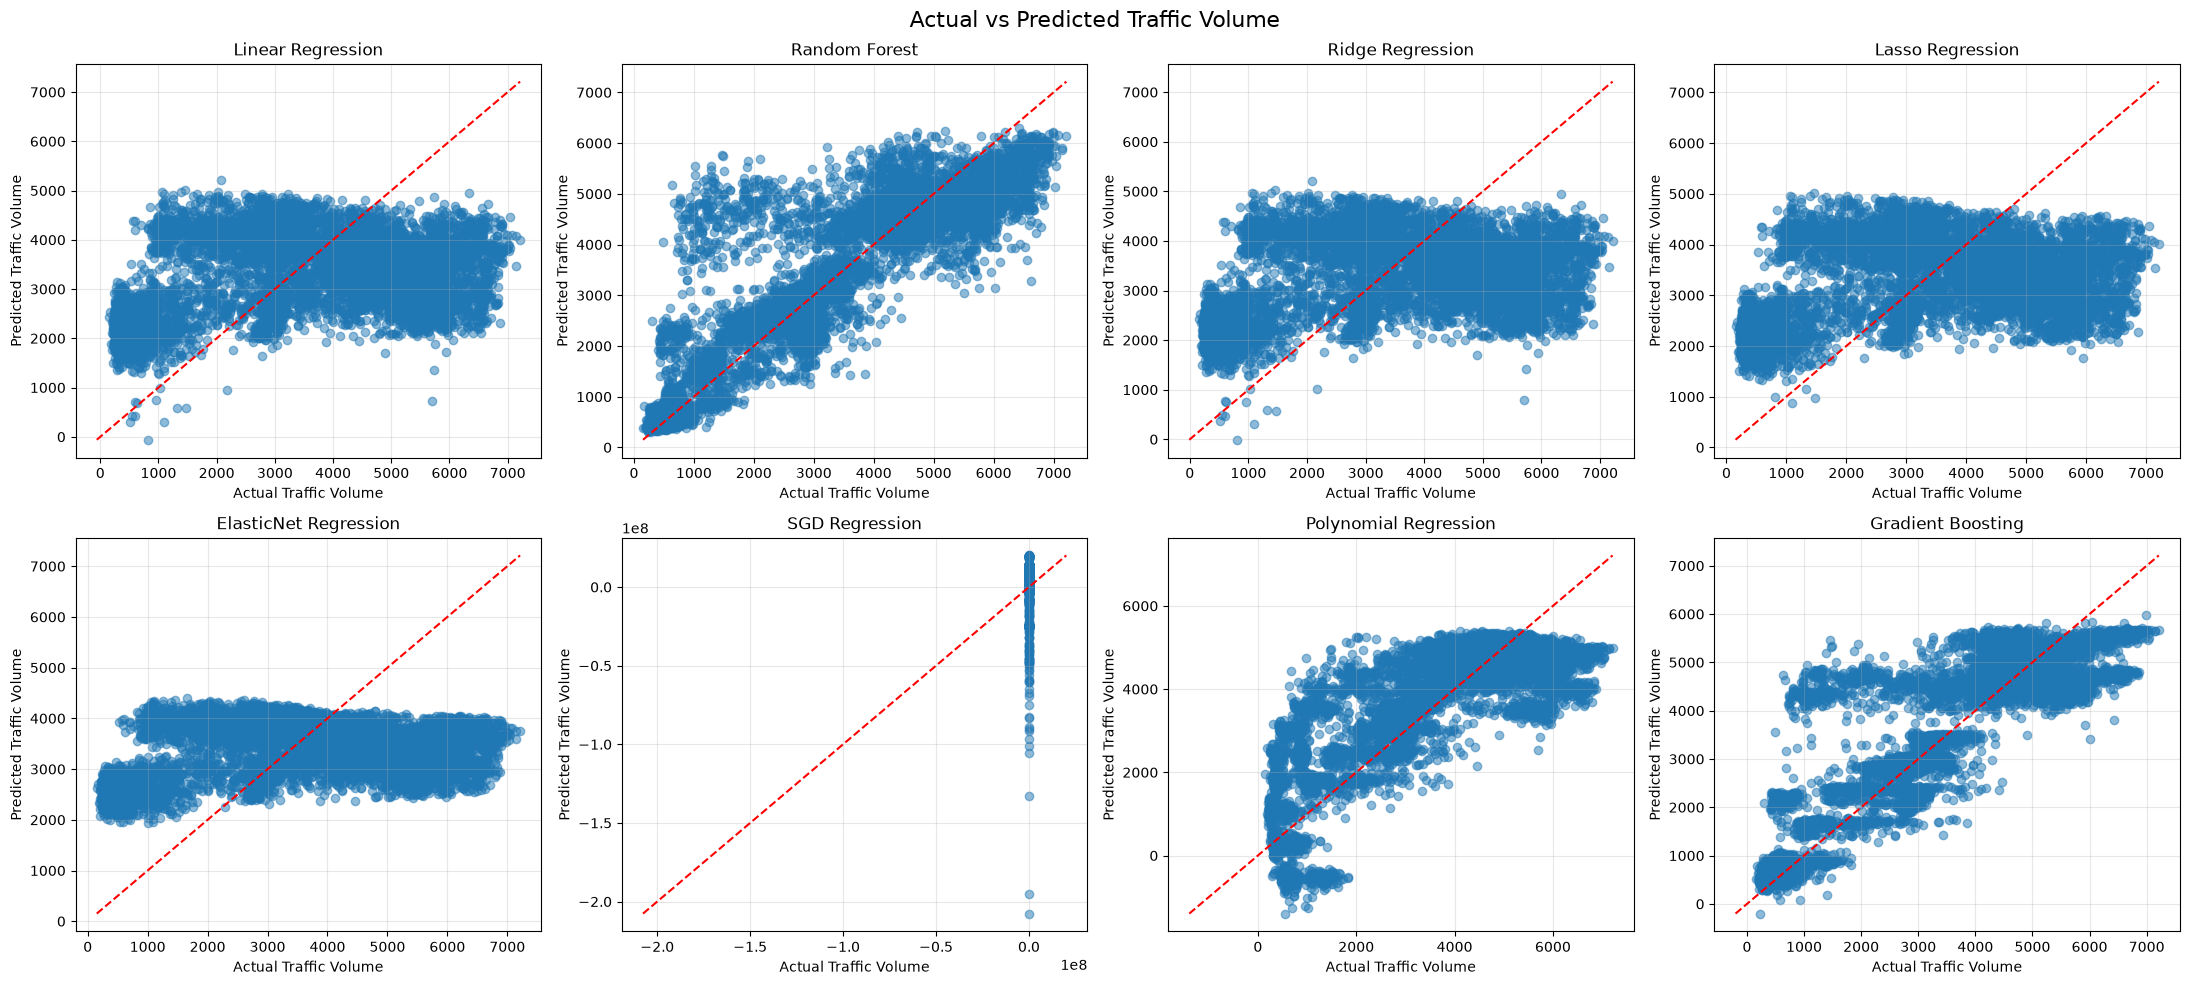

In [370]:
models = {
    "Linear Regression": Linear_Model,
    "Random Forest": RandomForest_Model,
    "Ridge Regression": Ridge_Model,
    "Lasso Regression": Lasso_Model,
    "ElasticNet Regression": ElasticNet_Model,
    "SGD Regression": SGD_Model,
    "Polynomial Regression": Polynomial_Model,
    "Gradient Boosting": GradientBoosting_Model
}
fig, axes = plt.subplots(2, 4, figsize=(22, 10))
axes = axes.flatten()

actual = np.asarray(y_test).ravel()

for ax, (name, model) in zip(axes, models.items()):
    predicted = np.asarray(model.predict(X_test)).ravel()
    ax.scatter(actual, predicted, alpha=0.5)

    low = min(actual.min(), predicted.min())
    high = max(actual.max(), predicted.max())
    ax.plot([low, high], [low, high], color="red", linestyle="--")

    ax.set_title(name)
    ax.set_xlabel("Actual Traffic Volume")
    ax.set_ylabel("Predicted Traffic Volume")
    ax.grid(alpha=0.3)

plt.suptitle("Actual vs Predicted Traffic Volume", fontsize=16)
plt.tight_layout()
plt.show()

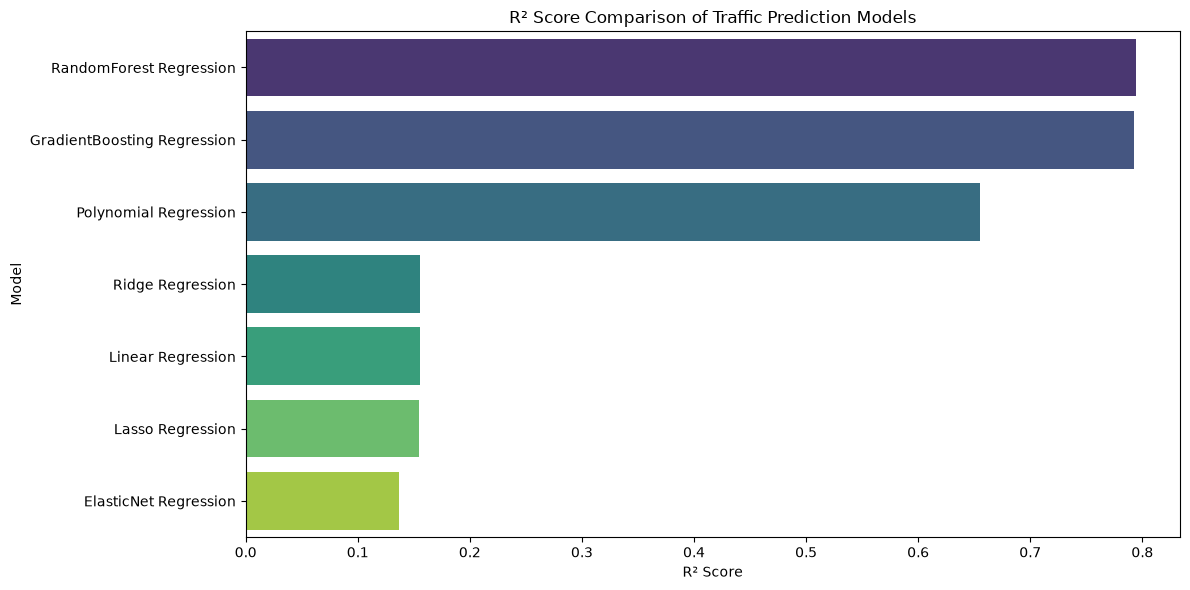

In [371]:
df_r2 = pd.DataFrame(results).T.reset_index().rename(columns={"index": "Model"})

# Exclude SGD without modifying original results
df_r2 = df_r2[df_r2["Model"] != "SGD Regression"]

df_r2 = df_r2.sort_values("R2 Score", ascending=False)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=df_r2,
    y="Model",
    x="R2 Score",
    hue="Model",
    palette="viridis",
    legend=False
)

plt.title("R² Score Comparison of Traffic Prediction Models")
plt.xlabel("R² Score")
plt.ylabel("Model")
plt.tight_layout()
plt.show()